In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content
!rm -rf /content/TRCAP
!git clone -b MC0 https://github.com/mhr871/TRCAP.git
%cd /content/TRCAP
!git rev-parse --short HEAD

/content
Cloning into 'TRCAP'...
remote: Enumerating objects: 289, done.
remote: Counting objects: 100% (289/289), done.
remote: Compressing objects: 100% (190/190), done.
remote: Total 289 (delta 153), reused 215 (delta 83), pack-reused 0 (from 0)
Receiving objects: 100% (289/289), 1.49 MiB | 4.45 MiB/s, done.
Resolving deltas: 100% (153/153), done.
/content/TRCAP
696adb2


In [3]:
!python -m pip install -r requirements_colab.txt
!python -m pip install --no-deps git+https://github.com/apple/ml-mobileclip.git
!python -c "import torch, transformers, timm, mobileclip; print('torch=', torch.__version__); print('transformers=', transformers.__version__); print('cuda=', torch.cuda.is_available())"

  Cloning https://github.com/salaniz/pycocoevalcap.git to /tmp/pip-req-build-bldyog31
  Running command git clone --filter=blob:none --quiet https://github.com/salaniz/pycocoevalcap.git /tmp/pip-req-build-bldyog31
  Resolved https://github.com/salaniz/pycocoevalcap.git to commit a24f74c408c918f1f4ec34e9514bc8a76ce41ffd
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 65.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 102.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 87.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 52.2 MB/s eta 0:00:00
  Created wheel for pycocoevalcap: filename=pycocoevalcap-1.2-py3-none-any.whl size=104

In [4]:
!python tools/prepare_tasviret.py --allow-missing-images
!python tools/download_tasviret_images.py
!python tools/prepare_tasviret.py --images-root Data/flickr8k/images

Raw split counts: {'train': 6000, 'val': 1000, 'test': 1000}
train: 6000 images, 12028 captions
val: 1000 images, 2006 captions
test: 1000 images, 2003 captions
TasvirEt split files are ready.
Downloading/reading data/train-00000-of-00002.parquet
data/train-00000-of-00002.parquet: 100% 415M/415M [00:04<00:00, 96.1MB/s]
Prepared 500/8000 images
Prepared 1000/8000 images
Prepared 1500/8000 images
Prepared 2000/8000 images
Prepared 2500/8000 images
Prepared 3000/8000 images
Downloading/reading data/train-00001-of-00002.parquet
data/train-00001-of-00002.parquet: 100% 413M/413M [00:02<00:00, 163MB/s]
Prepared 3500/8000 images
Prepared 4000/8000 images
Prepared 4500/8000 images
Prepared 5000/8000 images
Prepared 5500/8000 images
Prepared 6000/8000 images
Downloading/reading data/validation-00000-of-00001.parquet
data/validation-00000-of-00001.parquet: 100% 138M/138M [00:01<00:00, 112MB/s]
Prepared 6500/8000 images
Prepared 7000/8000 images
Downloading/reading data/test-00000-of-00001.parquet

In [5]:
!python tools/download_mobileclip.py --model mobileclip_s0

Done: /content/TRCAP/checkpoints/mobileclip_s0.pt (215934653 bytes)


# .........

# ingilizce deney 1 (mlp2 + mcs_0 + bert(baş))

In [6]:
!python tools/prepare_flickr8k_en.py

Raw split counts: {'train': 6000, 'val': 1000, 'test': 1000}
train: 6000 images, 30000 captions
val: 1000 images, 5000 captions
test: 1000 images, 5000 captions
[OK] All images referenced by the English split are present under /content/TRCAP/Data/flickr8k/images.


In [7]:
!PYTHONPATH=/content/TRCAP python tools/preflight_mobileclip.py \
  --config configs/tasviret/mobileclip_s0_stage1_en.yaml \
  --dataset flickr8k-en

[OK] Python 3.13.15
[OK] PyTorch 2.11.0+cu128, Transformers 4.38.2
[OK] GPU NVIDIA A100-SXM4-40GB, VRAM 39.49 GiB
[OK] train: 6000 images, 30000 captions
[OK] val: 1000 images, 5000 captions
[OK] test: 1000 images, 5000 captions
[OK] All 8000 referenced image files are present and disjoint by split
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
[OK] mobileclip package importable (module: /usr/local/lib/python3.13/dist-packages/mobileclip/__init__.py)
[OK] Checkpoint present: /content/TRCAP/checkpoints/mobileclip_s0.pt (215934653 bytes)
/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain 

In [8]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage1_en_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_stage1_en.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 15:39:30,328 WARNING] USE GPU: 0 for training
[2026-09-14 15:39:30,329 INFO] Namespace(config='configs/tasviret/mobileclip_s0_stage1_en.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s0_stage1_en_tasviret', overwrite=None, init_model_ckpt=None, strict_init=True, freeze_decoder=True, model={'mobileclip': 'mobileclip_s0', 'mobileclip_ckpt': 'checkpoints/mobileclip_s0.pt', 'image_size': 256, 'bert': 'bert-base-uncased', 'max_length': 35, 'proj': True, 'proj_num_head': None, 'proj_type': 'mlp2'}, lr='1e-5', lr_proj='1e-4', betas=[0.9, 0.99], weight_decay=0.01, num_workers=8, batch_size=128, max_iter=200,

In [9]:
!mkdir -p experiments/mobileclip_s0_stage1_en_tasviret
!cp /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage1_en_tasviret/model_last.pth \
    experiments/mobileclip_s0_stage1_en_tasviret/model_last.pth

In [10]:
!PYTHONPATH=/content/TRCAP python tools/preflight_mobileclip.py \
  --config configs/tasviret/mobileclip_s0_stage2_en.yaml --dataset flickr8k-en

[OK] Python 3.13.15
[OK] PyTorch 2.11.0+cu128, Transformers 4.38.2
[OK] GPU NVIDIA A100-SXM4-40GB, VRAM 39.49 GiB
[OK] train: 6000 images, 30000 captions
[OK] val: 1000 images, 5000 captions
[OK] test: 1000 images, 5000 captions
[OK] All 8000 referenced image files are present and disjoint by split
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
[OK] mobileclip package importable (module: /usr/local/lib/python3.13/dist-packages/mobileclip/__init__.py)
[OK] Checkpoint present: /content/TRCAP/checkpoints/mobileclip_s0.pt (215934653 bytes)
[OK] init_model_ckpt present: /content/TRCAP/experiments/mobileclip_s0_stage1_en_tasviret/model_last.pth (619353342 bytes)
/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setupt

In [11]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_en_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_stage2_en.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 15:42:15,154 WARNING] USE GPU: 0 for training
[2026-09-14 15:42:15,155 INFO] Namespace(config='configs/tasviret/mobileclip_s0_stage2_en.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s0_stage2_en_tasviret', overwrite=None, init_model_ckpt='experiments/mobileclip_s0_stage1_en_tasviret/model_last.pth', strict_init=True, freeze_decoder=False, model={'mobileclip': 'mobileclip_s0', 'mobileclip_ckpt': 'checkpoints/mobileclip_s0.pt', 'image_size': 256, 'bert': 'bert-base-uncased', 'max_length': 35, 'proj': True, 'proj_num_head': None, 'proj_type': 'mlp2'}, lr='1e-5', lr_proj='5e-5', betas=[0.9, 0.99], weigh

# ..........

# Train 1 / 3 (başla- trcap )

In [6]:
%cd /content/TRCAP
!PYTHONPATH=/content/TRCAP python tools/preflight_mobileclip.py \
  --config configs/tasviret/mobileclip_s0_stage1.yaml

/content/TRCAP
[OK] Python 3.13.15
[OK] PyTorch 2.11.0+cu128, Transformers 4.38.2
[OK] GPU NVIDIA A100-SXM4-40GB, VRAM 39.49 GiB
[OK] train: 6000 images, 12028 captions
[OK] val: 1000 images, 2006 captions
[OK] test: 1000 images, 2003 captions
[OK] All 8000 referenced image files are present and disjoint by split
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
[OK] mobileclip package importable (module: /usr/local/lib/python3.13/dist-packages/mobileclip/__init__.py)
[OK] Checkpoint present: /content/TRCAP/checkpoints/mobileclip_s0.pt (215934653 bytes)
/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-

In [7]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage1_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_stage1.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 11:31:31,550 WARNING] USE GPU: 0 for training
[2026-09-14 11:31:31,551 INFO] Namespace(config='configs/tasviret/mobileclip_s0_stage1.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s0_stage1_tasviret', overwrite=None, init_model_ckpt=None, strict_init=True, freeze_decoder=True, model={'mobileclip': 'mobileclip_s0', 'mobileclip_ckpt': 'checkpoints/mobileclip_s0.pt', 'image_size': 256, 'bert': 'dbmdz/bert-base-turkish-cased', 'max_length': 35, 'proj': True, 'proj_num_head': None, 'proj_type': 'mlp2'}, lr='1e-5', lr_proj='1e-4', betas=[0.9, 0.99], weight_decay=0.01, num_workers=8, batch_size=128, max_ite

In [8]:
!mkdir -p experiments/mobileclip_s0_stage1_tasviret
!cp /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage1_tasviret/model_last.pth \
    experiments/mobileclip_s0_stage1_tasviret/model_last.pth

In [9]:
!PYTHONPATH=/content/TRCAP python tools/preflight_mobileclip.py \
  --config configs/tasviret/mobileclip_s0_stage2.yaml

[OK] Python 3.13.15
[OK] PyTorch 2.11.0+cu128, Transformers 4.38.2
[OK] GPU NVIDIA A100-SXM4-40GB, VRAM 39.49 GiB
[OK] train: 6000 images, 12028 captions
[OK] val: 1000 images, 2006 captions
[OK] test: 1000 images, 2003 captions
[OK] All 8000 referenced image files are present and disjoint by split
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
[OK] mobileclip package importable (module: /usr/local/lib/python3.13/dist-packages/mobileclip/__init__.py)
[OK] Checkpoint present: /content/TRCAP/checkpoints/mobileclip_s0.pt (215934653 bytes)
/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain 

In [10]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_stage2.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 11:34:37,343 WARNING] USE GPU: 0 for training
[2026-09-14 11:34:37,343 INFO] Namespace(config='configs/tasviret/mobileclip_s0_stage2.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s0_stage2_tasviret', overwrite=None, init_model_ckpt='experiments/mobileclip_s0_stage1_tasviret/model_last.pth', strict_init=True, freeze_decoder=False, model={'mobileclip': 'mobileclip_s0', 'mobileclip_ckpt': 'checkpoints/mobileclip_s0.pt', 'image_size': 256, 'bert': 'dbmdz/bert-base-turkish-cased', 'max_length': 35, 'proj': True, 'proj_num_head': None, 'proj_type': 'mlp2'}, lr='1e-5', lr_proj='5e-5', betas=[0.9, 0.99], we

# **2**

In [20]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage1_proj_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_stage1_proj.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 12:11:33,959 WARNING] USE GPU: 0 for training
[2026-09-14 12:11:33,960 INFO] Namespace(config='configs/tasviret/mobileclip_s0_stage1_proj.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s0_stage1_proj_tasviret', overwrite=None, init_model_ckpt=None, strict_init=True, freeze_decoder=True, model={'mobileclip': 'mobileclip_s0', 'mobileclip_ckpt': 'checkpoints/mobileclip_s0.pt', 'image_size': 256, 'bert': 'dbmdz/bert-base-turkish-cased', 'max_length': 35, 'proj': True, 'proj_num_head': 16}, lr='1e-5', lr_proj='1e-4', betas=[0.9, 0.99], weight_decay=0.01, num_workers=8, batch_size=128, max_iter=200, warm_u

In [21]:
!mkdir -p experiments/mobileclip_s0_stage1_proj_tasviret
!cp /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage1_proj_tasviret/model_last.pth \
    experiments/mobileclip_s0_stage1_proj_tasviret/model_last.pth

In [22]:
!PYTHONPATH=/content/TRCAP python tools/preflight_mobileclip.py \
  --config configs/tasviret/mobileclip_s0_stage2_proj.yaml

[OK] Python 3.13.15
[OK] PyTorch 2.11.0+cu128, Transformers 4.38.2
[OK] GPU NVIDIA A100-SXM4-40GB, VRAM 39.49 GiB
[OK] train: 6000 images, 12028 captions
[OK] val: 1000 images, 2006 captions
[OK] test: 1000 images, 2003 captions
[OK] All 8000 referenced image files are present and disjoint by split
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
[OK] mobileclip package importable (module: /usr/local/lib/python3.13/dist-packages/mobileclip/__init__.py)
[OK] Checkpoint present: /content/TRCAP/checkpoints/mobileclip_s0.pt (215934653 bytes)
/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain 

In [23]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_proj_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_stage2_proj.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 12:14:33,516 WARNING] USE GPU: 0 for training
[2026-09-14 12:14:33,517 INFO] Namespace(config='configs/tasviret/mobileclip_s0_stage2_proj.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s0_stage2_proj_tasviret', overwrite=None, init_model_ckpt='experiments/mobileclip_s0_stage1_proj_tasviret/model_last.pth', strict_init=True, freeze_decoder=False, model={'mobileclip': 'mobileclip_s0', 'mobileclip_ckpt': 'checkpoints/mobileclip_s0.pt', 'image_size': 256, 'bert': 'dbmdz/bert-base-turkish-cased', 'max_length': 35, 'proj': True, 'proj_num_head': 16}, lr='1e-5', lr_proj='5e-5', betas=[0.9, 0.99], weight_dec

# **3**



In [7]:
%cd /content/TRCAP
!git pull
!python tools/download_checkpoint.py

/content/TRCAP
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 1.31 KiB | 1.31 MiB/s, done.
From https://github.com/mhr871/TRCAP
   15d9a26..bdc318f  MC0        -> origin/MC0
Updating 15d9a26..bdc318f
Fast-forward
 tools/preflight_mobileclip.py | 21 +++++++++++++++++++++
 1 file changed, 21 insertions(+)
Downloading...
From: https://drive.google.com/uc?id=1tOiRtIpe99gQWnpGfy_W5xgtsHFhvU3F
To: /content/TRCAP/checkpoints/TRCaptionNetpp_Large.pth
100% 2.44G/2.44G [00:27<00:00, 89.8MB/s]
Done: /content/TRCAP/checkpoints/TRCaptionNetpp_Large.pth (2438124871 bytes)


In [2]:
!python -m pip install -r requirements_colab.txt
!python -m pip install --no-deps git+https://github.com/apple/ml-mobileclip.git

  Cloning https://github.com/salaniz/pycocoevalcap.git to /tmp/pip-req-build-69x1__uh
  Running command git clone --filter=blob:none --quiet https://github.com/salaniz/pycocoevalcap.git /tmp/pip-req-build-69x1__uh
  Resolved https://github.com/salaniz/pycocoevalcap.git to commit a24f74c408c918f1f4ec34e9514bc8a76ce41ffd
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 69.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 118.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 84.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 47.5 MB/s eta 0:00:00
  Created wheel for pycocoevalcap: filename=pycocoevalcap-1.2-py3-none-any.whl size=104

In [3]:
!python tools/prepare_tasviret.py --allow-missing-images
!python tools/download_tasviret_images.py
!python tools/prepare_tasviret.py --images-root Data/flickr8k/images

Raw split counts: {'train': 6000, 'val': 1000, 'test': 1000}
train: 6000 images, 12028 captions
val: 1000 images, 2006 captions
test: 1000 images, 2003 captions
TasvirEt split files are ready.
Downloading/reading data/train-00000-of-00002.parquet
data/train-00000-of-00002.parquet: 100% 415M/415M [00:04<00:00, 96.6MB/s]
Prepared 500/8000 images
Prepared 1000/8000 images
Prepared 1500/8000 images
Prepared 2000/8000 images
Prepared 2500/8000 images
Prepared 3000/8000 images
Downloading/reading data/train-00001-of-00002.parquet
data/train-00001-of-00002.parquet: 100% 413M/413M [00:05<00:00, 76.7MB/s]
Prepared 3500/8000 images
Prepared 4000/8000 images
Prepared 4500/8000 images
Prepared 5000/8000 images
Prepared 5500/8000 images
Prepared 6000/8000 images
Downloading/reading data/validation-00000-of-00001.parquet
data/validation-00000-of-00001.parquet: 100% 138M/138M [00:01<00:00, 97.7MB/s]
Prepared 6500/8000 images
Prepared 7000/8000 images
Downloading/reading data/test-00000-of-00001.parqu

In [4]:
!python tools/download_mobileclip.py --model mobileclip_s0

Done: /content/TRCAP/checkpoints/mobileclip_s0.pt (215934653 bytes)


In [5]:
!PYTHONPATH=/content/TRCAP python tools/preflight_mobileclip.py \
  --config configs/tasviret/mobileclip_s0_proj_warmstart.yaml

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.
0it [00:00, ?it/s]
[OK] Python 3.13.15
[OK] PyTorch 2.11.0+cu128, Transformers 4.38.2
[OK] GPU NVIDIA A100-SXM4-40GB, VRAM 39.49 GiB
[OK] train: 6000 images, 12028 captions
[OK] val: 1000 images, 2006 captions
[OK] test: 1000 images, 2003 captions
[OK] All 8000 referenced image files are present and disjoint by split
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
[OK] mobileclip package importable (module: /usr/local/lib/python3.13/dist-packages/mobileclip/__init__.py)
[OK] Checkpoint present: /content/TRCAP/checkpoints/mobileclip_s0.

In [8]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_proj_warmstart_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_proj_warmstart.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 12:47:02,260 WARNING] USE GPU: 0 for training
[2026-09-14 12:47:02,260 INFO] Namespace(config='configs/tasviret/mobileclip_s0_proj_warmstart.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s0_proj_warmstart_tasviret', overwrite=None, init_model_ckpt='checkpoints/TRCaptionNetpp_Large.pth', strict_init=False, freeze_decoder=False, model={'mobileclip': 'mobileclip_s0', 'mobileclip_ckpt': 'checkpoints/mobileclip_s0.pt', 'image_size': 256, 'bert': 'dbmdz/bert-base-turkish-cased', 'max_length': 35, 'proj': True, 'proj_num_head': 16}, lr='1e-5', lr_proj='5e-5', betas=[0.9, 0.99], weight_decay=0.01, num_worke

# 4 - mlp2 + mc_s2 + bert(başlangıç)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
%cd /content
!rm -rf /content/TRCAP
!git clone -b MC0 https://github.com/mhr871/TRCAP.git
%cd /content/TRCAP
!git rev-parse --short HEAD

/content
Cloning into 'TRCAP'...
remote: Enumerating objects: 260, done.
remote: Counting objects: 100% (260/260), done.
remote: Compressing objects: 100% (174/174), done.
remote: Total 260 (delta 134), reused 193 (delta 71), pack-reused 0 (from 0)
Receiving objects: 100% (260/260), 1.48 MiB | 37.85 MiB/s, done.
Resolving deltas: 100% (134/134), done.
/content/TRCAP
a5b4334


In [2]:
!python -m pip install -r requirements_colab.txt
!python -m pip install --no-deps git+https://github.com/apple/ml-mobileclip.git

  Cloning https://github.com/salaniz/pycocoevalcap.git to /tmp/pip-req-build-wgm0kecv
  Running command git clone --filter=blob:none --quiet https://github.com/salaniz/pycocoevalcap.git /tmp/pip-req-build-wgm0kecv
  Resolved https://github.com/salaniz/pycocoevalcap.git to commit a24f74c408c918f1f4ec34e9514bc8a76ce41ffd
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 813.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 96.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 MB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 60.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 47.5 MB/s eta 0:00:00
  Created wheel for pycocoevalcap: filename=pycocoevalcap-1.2-py3-none-any.whl size=1043

In [3]:
!python tools/prepare_tasviret.py --allow-missing-images
!python tools/download_tasviret_images.py
!python tools/prepare_tasviret.py --images-root Data/flickr8k/images

Raw split counts: {'train': 6000, 'val': 1000, 'test': 1000}
train: 6000 images, 12028 captions
val: 1000 images, 2006 captions
test: 1000 images, 2003 captions
TasvirEt split files are ready.
Downloading/reading data/train-00000-of-00002.parquet
data/train-00000-of-00002.parquet: 100% 415M/415M [00:03<00:00, 129MB/s]
Prepared 500/8000 images
Prepared 1000/8000 images
Prepared 1500/8000 images
Prepared 2000/8000 images
Prepared 2500/8000 images
Prepared 3000/8000 images
Downloading/reading data/train-00001-of-00002.parquet
data/train-00001-of-00002.parquet: 100% 413M/413M [00:20<00:00, 20.2MB/s]
Prepared 3500/8000 images
Prepared 4000/8000 images
Prepared 4500/8000 images
Prepared 5000/8000 images
Prepared 5500/8000 images
Prepared 6000/8000 images
Downloading/reading data/validation-00000-of-00001.parquet
data/validation-00000-of-00001.parquet: 100% 138M/138M [00:01<00:00, 84.1MB/s]
Prepared 6500/8000 images
Prepared 7000/8000 images
Downloading/reading data/test-00000-of-00001.parque

In [4]:
!python tools/download_mobileclip.py --model mobileclip_s2

Done: /content/TRCAP/checkpoints/mobileclip_s2.pt (398067246 bytes)


In [5]:
!PYTHONPATH=/content/TRCAP python tools/preflight_mobileclip.py \
  --config configs/tasviret/mobileclip_s2_stage1.yaml

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.
0it [00:00, ?it/s]
[OK] Python 3.13.15
[OK] PyTorch 2.11.0+cu128, Transformers 4.38.2
[OK] GPU NVIDIA A100-SXM4-40GB, VRAM 39.49 GiB
[OK] train: 6000 images, 12028 captions
[OK] val: 1000 images, 2006 captions
[OK] test: 1000 images, 2003 captions
[OK] All 8000 referenced image files are present and disjoint by split
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
[OK] mobileclip package importable (module: /usr/local/lib/python3.13/dist-packages/mobileclip/__init__.py)
[OK] Checkpoint present: /content/TRCAP/checkpoints/mobileclip_s2.

In [6]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s2_stage1_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s2_stage1.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 13:25:44,789 WARNING] USE GPU: 0 for training
[2026-09-14 13:25:44,789 INFO] Namespace(config='configs/tasviret/mobileclip_s2_stage1.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s2_stage1_tasviret', overwrite=None, init_model_ckpt=None, strict_init=True, freeze_decoder=True, model={'mobileclip': 'mobileclip_s2', 'mobileclip_ckpt': 'checkpoints/mobileclip_s2.pt', 'image_size': 256, 'bert': 'dbmdz/bert-base-turkish-cased', 'max_length': 35, 'proj': True, 'proj_num_head': None, 'proj_type': 'mlp2'}, lr='1e-5', lr_proj='1e-4', betas=[0.9, 0.99], weight_decay=0.01, num_workers=8, batch_size=96, max_iter

In [7]:
!mkdir -p experiments/mobileclip_s2_stage1_tasviret
!cp /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s2_stage1_tasviret/model_last.pth \
    experiments/mobileclip_s2_stage1_tasviret/model_last.pth

In [8]:
!PYTHONPATH=/content/TRCAP python tools/preflight_mobileclip.py \
  --config configs/tasviret/mobileclip_s2_stage2.yaml

[OK] Python 3.13.15
[OK] PyTorch 2.11.0+cu128, Transformers 4.38.2
[OK] GPU NVIDIA A100-SXM4-40GB, VRAM 39.49 GiB
[OK] train: 6000 images, 12028 captions
[OK] val: 1000 images, 2006 captions
[OK] test: 1000 images, 2003 captions
[OK] All 8000 referenced image files are present and disjoint by split
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
[OK] mobileclip package importable (module: /usr/local/lib/python3.13/dist-packages/mobileclip/__init__.py)
[OK] Checkpoint present: /content/TRCAP/checkpoints/mobileclip_s2.pt (398067246 bytes)
[OK] init_model_ckpt present: /content/TRCAP/experiments/mobileclip_s2_stage1_tasviret/model_last.pth (730942364 bytes)
/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptool

In [9]:
!mkdir -p /content/drive/MyDrive/TRCAP_hibrit_runs
!rm -rf /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s2_stage2_tasviret
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s2_stage2.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 13:28:32,115 WARNING] USE GPU: 0 for training
[2026-09-14 13:28:32,116 INFO] Namespace(config='configs/tasviret/mobileclip_s2_stage2.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s2_stage2_tasviret', overwrite=None, init_model_ckpt='experiments/mobileclip_s2_stage1_tasviret/model_last.pth', strict_init=True, freeze_decoder=False, model={'mobileclip': 'mobileclip_s2', 'mobileclip_ckpt': 'checkpoints/mobileclip_s2.pt', 'image_size': 256, 'bert': 'dbmdz/bert-base-turkish-cased', 'max_length': 35, 'proj': True, 'proj_num_head': None, 'proj_type': 'mlp2'}, lr='1e-5', lr_proj='5e-5', betas=[0.9, 0.99], we

# resume 1(mlp2) / 2 (proj) / 3 başlangıç (trcap ile)

In [19]:
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_stage2.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs \
  --resume /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_tasviret/model_best.pth

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
[2026-09-14 12:03:25,293 WARNING] USE GPU: 0 for training
[2026-09-14 12:03:25,294 INFO] Namespace(config='configs/tasviret/mobileclip_s0_stage2.yaml', save_dir='/content/drive/MyDrive/TRCAP_hibrit_runs', resume=None, seed=42, gpu=0, save_name='mobileclip_s0_stage2_tasviret', overwrite=None, init_model_ckpt='experiments/mobileclip_s0_stage1_tasviret/model_last.pth', strict_init=True, freeze_decoder=False, model={'mobileclip': 'mobileclip_s0', 'mobileclip_ckpt': 'checkpoints/mobileclip_s0.pt', 'image_size': 256, 'bert': 'dbmdz/bert-base-turkish-cased', 'max_length': 35, 'proj': True, 'proj_num_head': None, 'proj_type': 'mlp2'}, lr='1e-5', lr_proj='5e-5', betas=[0.9, 0.99], we

In [ ]:
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_proj_warmstart.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs \
  --resume /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_proj_warmstart_tasviret/model_last.pth

In [ ]:
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s2_stage2.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs \
  --resume /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s2_stage2_tasviret/model_last.pth

# **5**

In [ ]:
!PYTHONPATH=/content/TRCAP python -u train.py \
  --config configs/tasviret/mobileclip_s0_stage2_en.yaml \
  --save-dir /content/drive/MyDrive/TRCAP_hibrit_runs \
  --resume /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_en_tasviret/model_last.pth

# ---------------------------------------------------------------------------






# caption karşılaştırma resimli /resimsiz      1 / 2

/content/TRCAP


/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist

[OK] Loaded /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_tasviret/model_last.pth onto cuda:0


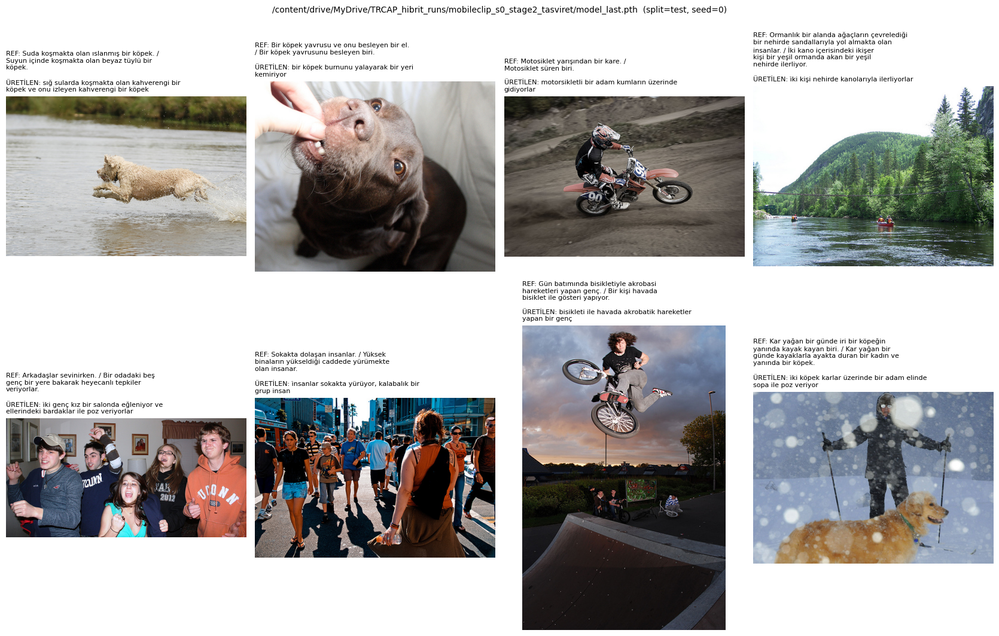

<Figure size 640x480 with 0 Axes>

In [11]:
%cd /content/TRCAP
%run tools/visualize_pairing.py \
  --config configs/tasviret/mobileclip_s0_stage2.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_tasviret/model_best.pth

In [12]:
!PYTHONPATH=/content/TRCAP python tools/check_pairing.py \
  --config configs/tasviret/mobileclip_s0_stage2.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_tasviret/model_best.pth

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertLMHeadModel were not initialized from the model checkpoint at dbmdz/bert-base-turkish-cased and are newly

# 2

In [30]:
!PYTHONPATH=/content/TRCAP python tools/check_pairing.py \
  --config configs/tasviret/mobileclip_s0_stage2_proj.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_proj_tasviret/model_last.pth

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertLMHeadModel were not initialized from the model checkpoint at dbmdz/bert-base-turkish-cased and are newly

/content/TRCAP


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertLMHeadModel were not initialized from the model checkpoint at dbmdz/bert-base-turkish-cased and are newly initialized: ['bert.encoder.layer.0.crossattention.output.LayerNorm.bias', 'bert.encoder.layer.0.crossattention.output.LayerNorm.weight', 'bert.encoder.layer.0.crossattention.output.dense.bias', 'bert.encoder.layer.0.crossattention.output.dense.weight', 'bert.encoder.layer.0.crossattention.self.key.bias', 'bert.encoder.layer.0.crossattention.self.key.weight', 'bert.encoder.layer.0.crossattention.self.query.bias', 'bert.encoder.layer.0.crossattention.self.query.weight', 'bert.encoder.layer.0.crossattention.self.value.bias', 'bert.encoder.layer.0.crossattention.self.value.weight', 'bert

[OK] Loaded /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_proj_tasviret/model_last.pth onto cuda:0


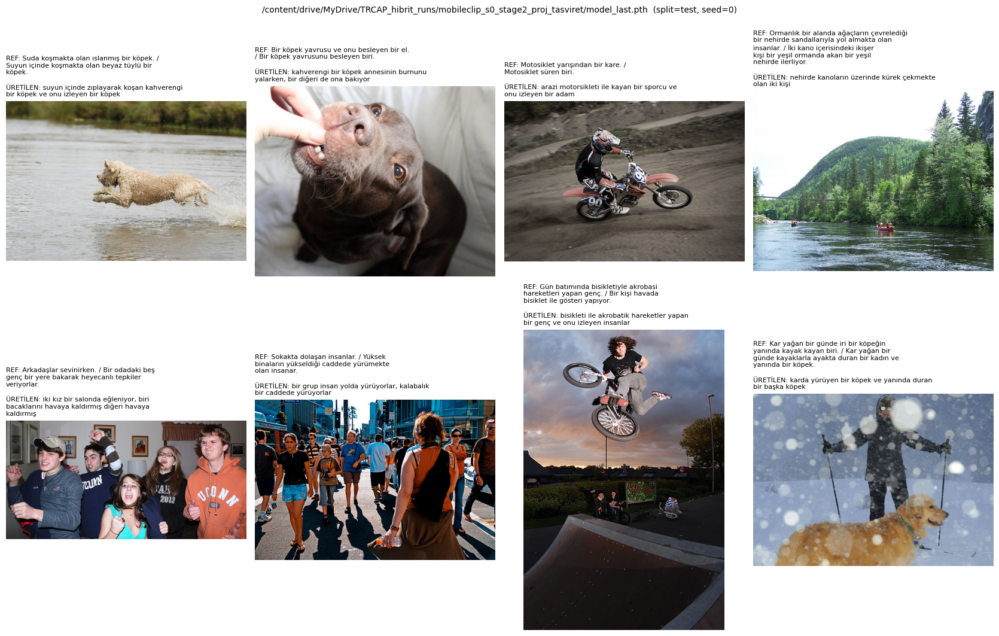

<Figure size 640x480 with 0 Axes>

In [29]:
%cd /content/TRCAP
%run tools/visualize_pairing.py \
  --config configs/tasviret/mobileclip_s0_stage2_proj.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_proj_tasviret/model_last.pth

# 3

In [9]:
!PYTHONPATH=/content/TRCAP python tools/check_pairing.py \
  --config configs/tasviret/mobileclip_s0_proj_warmstart.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_proj_warmstart_tasviret/model_last.pth

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertLMHeadModel were not initialized from the model checkpoint at dbmdz/bert-base-turkish-cased and are newly

/content/TRCAP


/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist

[OK] Loaded /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_proj_warmstart_tasviret/model_last.pth onto cuda:0


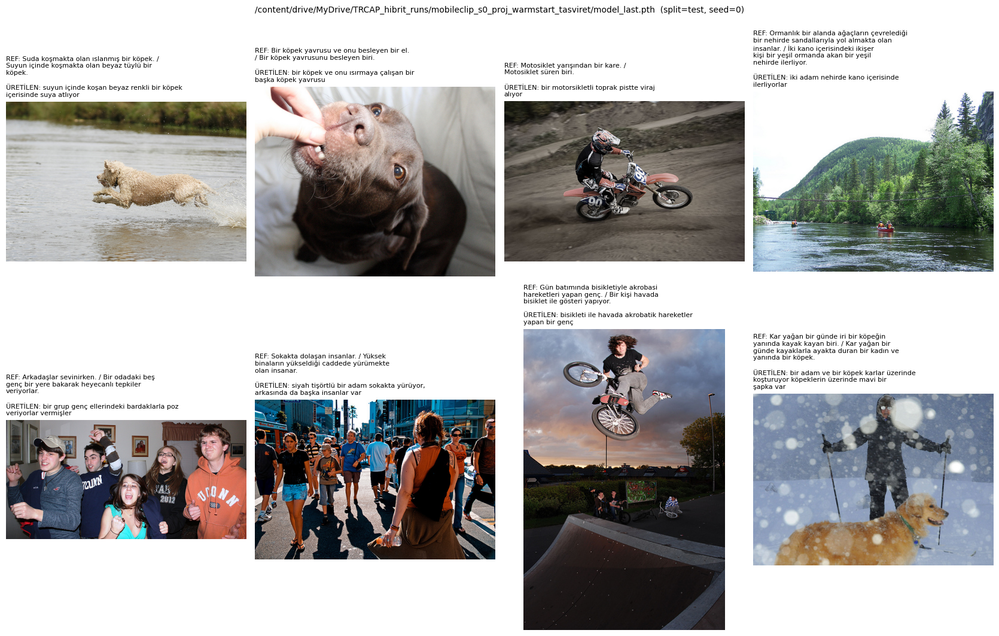

<Figure size 640x480 with 0 Axes>

In [10]:
%cd /content/TRCAP
%run tools/visualize_pairing.py \
  --config configs/tasviret/mobileclip_s0_proj_warmstart.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_proj_warmstart_tasviret/model_last.pth

# **4**

In [10]:
!PYTHONPATH=/content/TRCAP python tools/check_pairing.py \
  --config configs/tasviret/mobileclip_s2_stage2.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s2_stage2_tasviret/model_last.pth

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertLMHeadModel were not initialized from the model checkpoint at dbmdz/bert-base-turkish-cased and are newly

/content/TRCAP


/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist

[OK] Loaded /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s2_stage2_tasviret/model_last.pth onto cuda:0


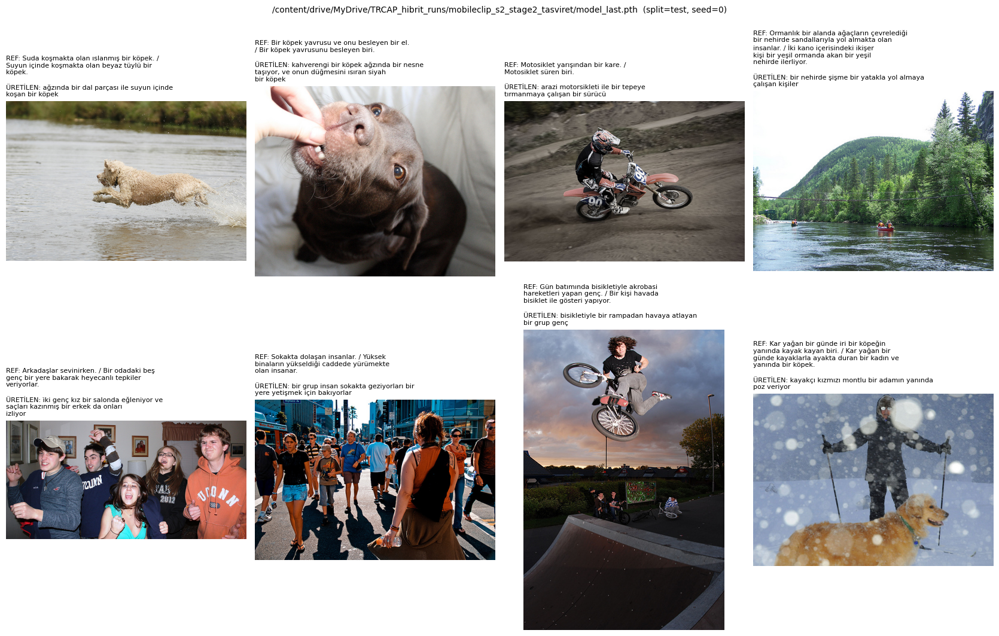

<Figure size 640x480 with 0 Axes>

In [11]:
%cd /content/TRCAP
%run tools/visualize_pairing.py \
  --config configs/tasviret/mobileclip_s2_stage2.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s2_stage2_tasviret/model_last.pth

# **5**

In [12]:
!PYTHONPATH=/content/TRCAP python tools/check_pairing.py \
  --config configs/tasviret/mobileclip_s0_stage2_en.yaml \
  --weights /content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s0_stage2_en_tasviret/model_last.pth \
  --data-dir Data/flickr8k-en --json-prefix flickr8k

/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertLMHeadModel were not initialized from the model checkpoint at bert-base-uncased and are newly initialized

# Tokenizer teshisi: PTBTokenizer Turkce karakterleri bozuyor mu?

`check_pairing.py` ciktilarinda caption'lar iceriksel olarak dogru gorunuyor
(kopek suya atliyor, motosiklet, kano, vb.) ama Bleu_4/CIDEr egitim boyunca
duzelmiyor, hatta duesueyor. Bu, modelin degil OLCUM hattinin bozuk olabilecegini
dusundueruyor: `eval.py`'nin kullandigi `PTBTokenizer`, Ingilizce/Java tabanli bir
arac ve Turkce'ye ozgu karakterleri (I/i/i-nokta, s, g, u, o, c) hic test edilmeden
kullaniliyor. Bu hucre, referans/uretilmis caption ciftlerini ayni PTBTokenizer
yolundan gecirip token ciktisini yan yana basar -- Java zaten Colab'da kurulu
oldugu icin (METEOR scorer daha once gercekten calisip coktu) GPU gerekmez,
saniyeler icinde biter.

In [ ]:
%cd /content/TRCAP
!PYTHONPATH=/content/TRCAP python tools/check_tokenization.py

# ---------------------------------------------------------------------------

#  TEST - DEMO 1 / 2

In [16]:
import os

%cd /content/TRCAP
!git pull

from google.colab import files
uploaded = files.upload()
image_path = next(iter(uploaded.keys()))

# Define the weights path and config path for a successfully trained model
weights_path = '/content/drive/MyDrive/TRCAP_hibrit_runs/mobileclip_s2_stage2_tasviret/model_last.pth'
config_path = 'configs/tasviret/mobileclip_s2_stage2.yaml'

# Check if the weights file exists before running the inference
if not os.path.exists(weights_path):
    print(f"Error: Weights file not found at {weights_path}. Please ensure the model was trained successfully.")
else:
    !PYTHONPATH=/content/TRCAP python tools/infer_image.py \
      --image "{image_path}" \
      --config "{config_path}" \
      --weights "{weights_path}"

/content/TRCAP
Already up to date.


Saving COCO_val2014_000000000962.jpg to COCO_val2014_000000000962.jpg
/content/TRCAP/Model/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertLMHeadModel were not initialized fr

In [ ]:
!pip install "gradio>=4.0.0,<5.0.0" "sentence-transformers==2.5.1" --upgrade

  Preparing metadata (setup.py) ... done
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 377, in run
    requirement_set = resolver.resolve(
        reqs, check_supported_wheels=not options.target_dir
    )
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/resolution/resolvelib/resolver.py", line 95, in resolve
    result = self._result = resolver.resolve(
                            ~~~~~~~~~~~~~~~~^
        collected.requirements, max_rounds=limit_how_complex_resolution_can_be
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/pip